<a href="https://colab.research.google.com/github/murtaza-aiml/python_ai_ml/blob/main/Train_Test_Split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# --- 1. MOCK DATA INITIALIZATION ---
# Simulating your exact distribution mapping parameters locally
raw_data = {
    'RD_Spend': [165349.2, 0.0, 153441.5, 144372.4, 0.0, 45173.0, 131876.9, 0.0, 120542.5],
    'Administration': [136897.8, 91391.7, 101145.5, 118671.8, 142107.3, 99814.7, 151377.6, 85000.0, 148000.0],
    'Marketing_Spend': [471784.1, 0.0, 407934.5, 383199.6, 0.0, 362861.3, 252661.3, 0.0, 310500.0],
    'Location': ['New York', 'Texas', 'California', 'New York', 'Florida', 'Ohio', 'California', 'Illinois', 'New York'],
    'Profit': [192261.8, 155000.0, 191050.4, 182901.9, 166187.9, 145000.0, 156991.1, 138000.0, 152000.0]
}

df_startups = pd.DataFrame(raw_data)
print("--- Raw Production Startup Grid ---")
print(df_startups)


# ==========================================
# === STEP 1: CONSTRAIN THE 20 LOCATIONS ===
# ==========================================
# Retain power-player states; compress the other 16 long-tail profiles into 'Other'
top_power_states = ['New York', 'California']

df_startups['Location_Cleaned'] = df_startups['Location'].apply(
    lambda x: x if x in top_power_states else 'Other'
)


# ==========================================
# === STEP 2: FLAG ORGANIC EXTRACTIONS  ===
# ==========================================
# Flag companies that command massive profits with 0 R&D/Marketing overhead
df_startups['Is_Organic_Service'] = np.where(
    (df_startups['RD_Spend'] == 0.0) & (df_startups['Marketing_Spend'] == 0.0),
    1.0,
    0.0
)


# ==========================================
# === STEP 3: EXECUTE ONE-HOT ENCODING  ===
# ==========================================
# Drop first column to insulate matrix against structural multicollinearity
df_encoded = pd.get_dummies(
    df_startups,
    columns=['Location_Cleaned'],
    drop_first=True,
    dtype=float
).drop(columns=['Location']) # Drop the raw uncleaned text location column


# ==========================================
# === STEP 4: TRAIN / TEST DATA SPLIT   ===
# ==========================================
X = df_encoded.drop(columns=['Profit'])
y = df_encoded['Profit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)


# ==========================================
# === STEP 5: MODEL FIT & ACCURACY EXAM ===
# ==========================================
startup_model = LinearRegression()
startup_model.fit(X_train, y_train)

# Calculate model generalization score strictly using the hidden test pool
test_score = startup_model.score(X_test, y_test)



# ==========================================
# === EVALUATION MATRIX REPORT ===
# ==========================================
print("\n=== Trained Feature Weights Matrix ===")
for feature_name, weight_value in zip(X.columns, startup_model.coef_):
    print(f"Weight for {feature_name:30}: ${weight_value:,.2f}")

print(f"\nModel Baseline Shift Bias (Intercept):  ${startup_model.intercept_:,.2f}")
print(f"Generalization Exam Pool R² Score:      {test_score:.4f} ({test_score*100:.1f}%)")



--- Raw Production Startup Grid ---
   RD_Spend  Administration  Marketing_Spend    Location    Profit
0  165349.2        136897.8         471784.1    New York  192261.8
1       0.0         91391.7              0.0       Texas  155000.0
2  153441.5        101145.5         407934.5  California  191050.4
3  144372.4        118671.8         383199.6    New York  182901.9
4       0.0        142107.3              0.0     Florida  166187.9
5   45173.0         99814.7         362861.3        Ohio  145000.0
6  131876.9        151377.6         252661.3  California  156991.1
7       0.0         85000.0              0.0    Illinois  138000.0
8  120542.5        148000.0         310500.0    New York  152000.0

=== Trained Feature Weights Matrix ===
Weight for RD_Spend                      : $0.93
Weight for Administration                : $-0.39
Weight for Marketing_Spend               : $-0.03
Weight for Is_Organic_Service            : $59,537.42
Weight for Location_Cleaned_New York     : $6,169.2

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# --- 1. MOCK DATA INITIALIZATION ---
raw_data = {
    'RD_Spend': [165349.2, 0.0, 153441.5, 144372.4, 0.0, 45173.0, 131876.9, 0.0, 120542.5],
    'Administration': [136897.8, 91391.7, 101145.5, 118671.8, 142107.3, 99814.7, 151377.6, 85000.0, 148000.0],
    'Marketing_Spend': [471784.1, 0.0, 407934.5, 383199.6, 0.0, 362861.3, 252661.3, 0.0, 310500.0],
    'Location': ['New York', 'Texas', 'California', 'New York', 'Florida', 'Ohio', 'California', 'Illinois', 'New York'],
    'Profit': [192261.8, 155000.0, 191050.4, 182901.9, 166187.9, 145000.0, 156991.1, 138000.0, 152000.0]
}

df_startups = pd.DataFrame(raw_data)

# ==========================================
# === STEP 1: DROP THE LOCATION FEATURE ===
# ==========================================
# Completely eliminate the Location column right at the beginning of the pipeline
df_startups = df_startups.drop(columns=['Location'])


# ==========================================
# === STEP 2: FLAG ORGANIC EXTRACTIONS  ===
# ==========================================
# We keep this feature flag so the model can still understand 0-spending companies
df_startups['Is_Organic_Service'] = np.where(
    (df_startups['RD_Spend'] == 0.0) & (df_startups['Marketing_Spend'] == 0.0),
    1.0,
    0.0
)


# ==========================================
# === STEP 3: TRAIN / TEST DATA SPLIT   ===
# ==========================================
X = df_startups.drop(columns=['Profit'])
y = df_startups['Profit']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)


# ==========================================
# === STEP 4: MODEL FIT & ACCURACY EXAM ===
# ==========================================
startup_model = LinearRegression()
startup_model.fit(X_train, y_train)

# Calculate model generalization score strictly using the hidden test pool
test_score = startup_model.score(X_test, y_test)


# ==========================================
# === EVALUATION MATRIX REPORT ===
# ==========================================
print("=== Trained Feature Weights Matrix (No Location) ===")
for feature_name, weight_value in zip(X.columns, startup_model.coef_):
    print(f"Weight for {feature_name:25}: ${weight_value:,.2f}")

print(f"\nModel Baseline Shift Bias (Intercept):  ${startup_model.intercept_:,.2f}")
print(f"Generalization Exam Pool R² Score:      {test_score:.4f} ({test_score*100:.1f}%)")


=== Trained Feature Weights Matrix (No Location) ===
Weight for RD_Spend                 : $0.67
Weight for Administration           : $-0.30
Weight for Marketing_Spend          : $0.04
Weight for Is_Organic_Service       : $104,593.27

Model Baseline Shift Bias (Intercept):  $103,889.41
Generalization Exam Pool R² Score:      -22.3589 (-2235.9%)


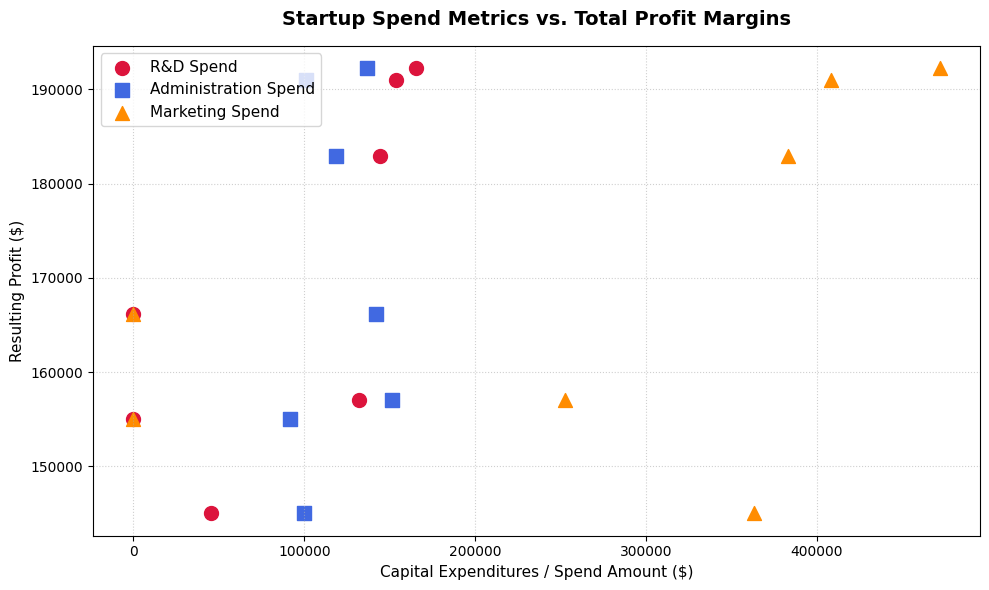

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. SAMPLE STARTUP DATA ---
raw_data = {
    'RD_Spend': [165349.2, 0.0, 153441.5, 144372.4, 0.0, 45173.0, 131876.9],
    'Administration': [136897.8, 91391.7, 101145.5, 118671.8, 142107.3, 99814.7, 151377.6],
    'Marketing_Spend': [471784.1, 0.0, 407934.5, 383199.6, 0.0, 362861.3, 252661.3],
    'Profit': [192261.8, 155000.0, 191050.4, 182901.9, 166187.9, 145000.0, 156991.1]
}
df_startups = pd.DataFrame(raw_data)

# ==========================================
# === MATPLOTLIB MULTI-SERIES CANVAS ===
# ==========================================
plt.figure(figsize=(10, 6))

# Series 1: R&D Spend vs Profit (Crimson circles)
plt.scatter(df_startups['RD_Spend'], df_startups['Profit'],
            color='crimson', marker='o', s=100, label='R&D Spend')

# Series 2: Administration vs Profit (Royal blue squares)
plt.scatter(df_startups['Administration'], df_startups['Profit'],
            color='royalblue', marker='s', s=100, label='Administration Spend')

# Series 3: Marketing Spend vs Profit (Dark orange triangles)
plt.scatter(df_startups['Marketing_Spend'], df_startups['Profit'],
            color='darkorange', marker='^', s=100, label='Marketing Spend')

# ==========================================
# === FORMAT LABELS & ANNOTATIONS ===
# ==========================================
plt.title('Startup Spend Metrics vs. Total Profit Margins', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Capital Expenditures / Spend Amount ($)', fontsize=11)
plt.ylabel('Resulting Profit ($)', fontsize=11)

# Enable gridlines and place the bounding box legend to identify the features
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper left')

plt.tight_layout()
plt.show()
